# 8-SAT: QAOA Pretraining and Sparrow

共享输入：**n=10、m=176、k=8**。重新训练 p=1、2、3，主电路采用 p=3。每种方法统计 1000 次；无纠错。

In [1]:
from pathlib import Path
import csv, html, json, os, re, statistics, subprocess, tempfile, time, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from scipy.optimize import minimize
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector

CNF_NAME = 'instance_8sat_n10_m176_seed20261116.cnf'
K = 8
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p/'data'/CNF_NAME).is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open this notebook inside the qaoa_aa_3sat project.')
OUTPUT = PROJECT/'results/8sat_n10_m176/pretrain'
OUTPUT.mkdir(parents=True, exist_ok=True)
P_VALUES, P_SELECTED = [1, 2, 3], 3
RESTARTS, MAXITER = 3, 100
TRAIN_SEED, SHOT_SEED = 2410, 5109
SHOTS, SPARROW_RUNS = 1000, 1000
COLORS = ['#245b8b', '#007c83', '#c96d2e']
plt.rcParams.update({'figure.dpi':115, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})

def show_table(rows):
    keys = list(rows[0])
    header = ''.join(f'<th>{html.escape(str(k))}</th>' for k in keys)
    body = ''.join('<tr>'+''.join(f'<td>{html.escape(str(row[k]))}</td>'
                                for k in keys)+'</tr>' for row in rows)
    display(HTML('<table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table>'))

def write_csv(name, rows):
    with (OUTPUT/name).open('w', encoding='utf-8-sig', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

print('Shared input:', PROJECT/'data'/CNF_NAME)
print('Demo outputs:', OUTPUT)

Shared input: C:\Users\yanxi\.codex\.chatgpt-projects\g-p-6ab3fde64d14819191c93e2b0a8fa871\work\eight_sat_n10_m176_20261116\qaoa_aa_3sat\data\instance_8sat_n10_m176_seed20261116.cnf
Demo outputs: C:\Users\yanxi\.codex\.chatgpt-projects\g-p-6ab3fde64d14819191c93e2b0a8fa871\work\eight_sat_n10_m176_20261116\qaoa_aa_3sat\results\8sat_n10_m176\pretrain


## 1. 共同输入：10 个变量、176 个 8-literal 子句

DIMACS 头部为 `p cnf 10 176`。每个子句包含 **8 个不同变量**，正负文字随机生成。子句内部为“或”，176 个子句之间为“且”。同一份 CNF 同时交给 Sparrow 与量子电路。

实例固定种子 20261116，拒绝重复子句，没有预先植入答案。下方枚举全部 1024 个赋值，仅用于这个小实例的核验。密度为 $m/n=17.6$。

In [2]:
cnf_text = (PROJECT/'data'/CNF_NAME).read_text(encoding='ascii')
lines = [line.strip() for line in cnf_text.splitlines()
         if line.strip() and not line.lstrip().startswith('c')]
kind, form, n_text, m_text = lines[0].split()
assert (kind, form) == ('p', 'cnf')
N, M = int(n_text), int(m_text)
clauses = []
for line in lines[1:]:
    literals = list(map(int, line.split()))
    assert literals[-1] == 0 and 0 not in literals[:-1]
    assert len(literals[:-1]) == K
    clause = [(abs(v)-1, v > 0) for v in literals[:-1]]
    assert all(0 <= i < N for i, _ in clause)
    assert len({i for i, _ in clause}) == K
    clauses.append(clause)
assert (N, M, K) == (10, 176, 8) and len(clauses) == M
print(lines[0]); print('First 6 of 176 clauses:'); print('\n'.join(lines[1:7]))
assert len({tuple(c) for c in clauses}) == M

p cnf 10 176
First 6 of 176 clauses:
-3 -4 -5 6 -7 8 9 10 0
-1 -4 -5 -6 -7 8 9 -10 0
-2 -3 -4 -5 6 -7 8 -10 0
2 -3 4 5 -6 7 -8 10 0
1 -2 -4 -5 -7 -8 9 10 0
1 -2 -3 4 -5 -6 -9 -10 0


## 2. 论文成本与 8-SAT 相位器

子句满足时 $C_j(x)=1$。沿用论文式 (4)：
$$H_C(x)=-\sum_{j=1}^{176}C_j(x).$$
全部满足时成本为 $-176$。每个 8-literal 子句的唯一失败图样得到 $e^{-i\gamma}$，并保留全局相位 $e^{i176\gamma}$。mixer 仍按 $H_M=\frac12\sum_iX_i$ 使用 $R_x(\beta)$。

In [3]:
def paper_cost_diagonal(n, clauses):
    """Diagonal of the paper's H_C = -sum_j C_j, Eq. (4).

    Evaluate satisfied clauses directly. The violation count remains only a
    diagnostic; it is not a second Hamiltonian or the optimizer's objective.
    """
    states = np.arange(1 << n, dtype=np.int64)
    cost_diagonal = np.zeros(1 << n, dtype=np.int64)
    for clause in clauses:
        satisfied = np.zeros(1 << n, dtype=bool)
        for i, positive in clause:
            bit = ((states >> i) & 1).astype(bool)
            satisfied |= bit if positive else ~bit
        cost_diagonal -= satisfied
    return cost_diagonal

cost_diagonal = paper_cost_diagonal(N, clauses)
good = cost_diagonal == -M
uniform_success = float(good.mean())
print(f'n={N}, m={M}; SAT assignments={int(good.sum())}/{1<<N}')
print(f'Uniform success probability: {100*uniform_success:.4f}%')
print('Lowest possible cost:', -M)
assert np.any(good) and np.any(~good)

n=10, m=176; SAT assignments=513/1024
Uniform success probability: 50.0977%
Lowest possible cost: -176


**γ 和 β 控制什么？** 每层先执行 $e^{-i\gamma H_C}$，再执行 $e^{-i\beta H_M}$。

- γ 控制按子句成本施加的相位；分色只改变子句的执行批次，不改变成本。
- 按论文 $H_M=\frac12\sum_iX_i$ 的约定，β 对应每个数据位上的 $R_x(\beta)$。

每个子句的唯一失败图样先得到 $e^{-i\gamma}$，再给所有状态补 $e^{+i\gamma}$：失败图样的相位抵消为 1，满足图样留下 $e^{+i\gamma}$。这正好等于该子句的 $e^{-i\gamma(-C_j)}$。

一层中每个子句补 $+\gamma$，所以总整体相位是 $+m\gamma$。它由 γ 自动计算，**没有另一个待训练的“整体相位参数”**。

In [4]:
def greedy_clause_colors(clauses):
    """A valid greedy coloring, not a claim of minimum chromatic number."""
    batches = []
    used = []
    for j, clause in enumerate(clauses):
        variables = {i for i, _ in clause}
        for b, occupied in enumerate(used):
            if not variables & occupied:
                batches[b].append(j)
                occupied.update(variables)
                break
        else:
            batches.append([j]); used.append(set(variables))
    return batches

def phaser_circuit(n, clauses, gamma):
    qc = QuantumCircuit(n, name='phaser')
    for batch in greedy_clause_colors(clauses):
        for j in batch:
            clause = clauses[j]
            positive = [i for i, sign in clause if sign]
            variables = [i for i, _ in clause]
            if positive: qc.x(positive)
            # Paper Eq. (4): H_C = -#SAT = #UNSAT-m; mark failure with -gamma.
            qc.mcp(-float(gamma), variables[:-1], variables[-1])
            if positive: qc.x(positive)
    # e^{-i gamma H_C} = e^{+i gamma m} e^{-i gamma #UNSAT}.
    qc.global_phase += float(gamma) * len(clauses)
    return qc

In [5]:
def mixer_circuit(n, beta):
    qc = QuantumCircuit(n, name='mixer')
    qc.rx(float(beta), range(n))  # H_M = (1/2) sum X, paper Eq. (3).
    return qc

def qaoa_circuit(n, clauses, gammas, betas, boxed=False):
    qc = QuantumCircuit(n, name='A=U H')
    qc.h(range(n))
    for layer, (gamma, beta) in enumerate(zip(gammas, betas), start=1):
        ph = phaser_circuit(n, clauses, gamma)
        mix = mixer_circuit(n, beta)
        if boxed:
            qc.append(ph.to_gate(label=f'phaser {layer}: gamma={gamma:.3f}'), range(n))
            qc.append(mix.to_gate(label=f'mixer {layer}: beta={beta:.3f}'), range(n))
        else:
            qc.compose(ph, inplace=True)
            qc.compose(mix, inplace=True)
    qc.metadata = {'qaoa_parameters': {'gammas': list(map(float, gammas)), 'betas': list(map(float, betas))}}
    return qc

下面展开实际 $C_1$ 的 **8 根数据线**。演示角度 0.371 不用于训练。完整 10 位相位器仍包含全部 176 个子句，并核对全部 1024 个赋值的复振幅。

本例任意两个子句都至少共享 $8+8-10=6$ 个变量，因此贪心分色有 176 批；不能把这些子句作为互不占用数据位的模块同时运行。

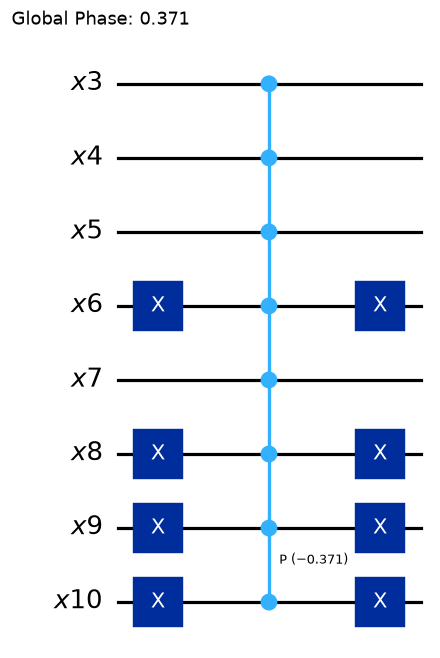

PASS: paper Eq. (4) phase on all 1024 assignments, max error=5.98e-14


In [6]:
probe_gamma = 0.371
local_clause = [[(q, positive) for q, (_, positive) in enumerate(clauses[0])]]
first_clause_circuit = phaser_circuit(K, local_clause, probe_gamma)
named_clause = QuantumCircuit(*[QuantumRegister(1, f'x{i+1}') for i, _ in clauses[0]])
named_clause.compose(first_clause_circuit, inplace=True)
first_clause_circuit = named_clause
display(first_clause_circuit.draw('mpl', fold=-1))
plt.close('all')

probe = QuantumCircuit(N)
probe.h(range(N))
probe.compose(phaser_circuit(N, clauses, probe_gamma), inplace=True)
actual = Statevector.from_instruction(probe).data
expected = np.exp(-1j*probe_gamma*cost_diagonal)/np.sqrt(1<<N)
phase_error = float(np.max(np.abs(actual-expected)))
assert phase_error < 1e-10
print(f'PASS: paper Eq. (4) phase on all 1024 assignments, max error={phase_error:.3g}')

### 2.1 把全局相位画在电路上

上一张图左上角的 **Global Phase: 0.371** 就是全局相位。代码中施加它的语句是：

```python
qc.global_phase += float(gamma) * len(clauses)
```

Qiskit 将它记录在整条电路上，默认不画在线上。为了汇报时能看见，下方把同一个操作画成跨越所有量子线的 **$e^{i\phi}I$ 方块**。$I$ 表示所有位的取值都不变，只让整个状态乘 $e^{i\phi}$。

这个方块内部只有 `global_phase`，没有隐藏的 X、控制门或额外量子位；它是对同一个酉算符的画图表示，不表示需要额外的硬件门或独立训练参数。单独的全局相位不改变测量概率，不能用某一根线上的普通 $P(\phi)$ 门代替。

先用同一条 8 位子句举例：`X → 受控 P(-0.371) → X` 后面，显式接上 $e^{+i0.371}I$。下面比较完整复振幅，确认两种画法相同。

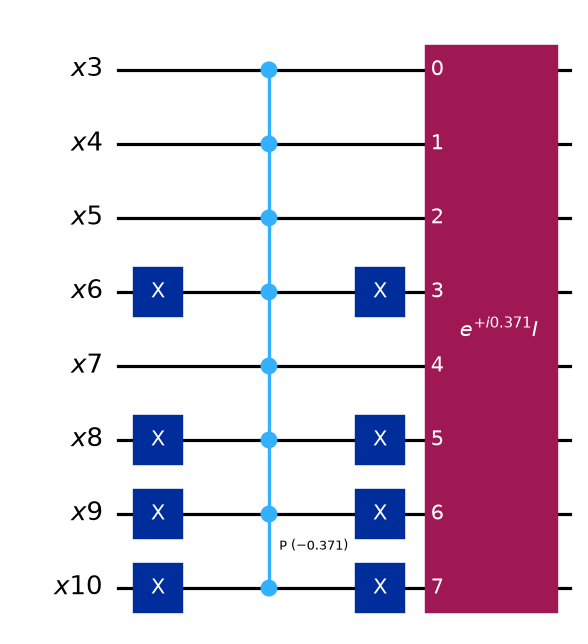

PASS: native and explicit global phase agree, max error=1.55e-16


In [7]:
def expose_global_phase(circuit, label):
    """把电路顶部的全局相位，等价地显示成跨越全部量子线的方块。"""
    visible = circuit.copy()
    angle = float(visible.global_phase)
    visible.global_phase = 0  # 移到下面的方块中，避免重复乘一次相位。

    phase_identity = QuantumCircuit(visible.num_qubits, name='global_phase')
    phase_identity.global_phase = angle  # 这个方块的全部作用：e^(i*angle) I。
    visible.append(phase_identity.to_gate(label=label), visible.qubits)
    return visible

explicit_clause = expose_global_phase(
    first_clause_circuit, rf'$e^{{+i{probe_gamma:.3f}}} I$')
fig = explicit_clause.draw('mpl', fold=-1)
fig.savefig(OUTPUT/'clause_with_explicit_global_phase.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

toy_native = QuantumCircuit(K); toy_native.h(range(K))
toy_explicit = toy_native.copy()
toy_native.compose(first_clause_circuit, inplace=True)
toy_explicit.compose(explicit_clause, inplace=True)
clause_view_error = float(np.max(np.abs(
    Statevector.from_instruction(toy_native).data
    - Statevector.from_instruction(toy_explicit).data)))
assert clause_view_error < 1e-10
print(f'PASS: native and explicit global phase agree, max error={clause_view_error:.3g}')

## 3. 重新训练 γ 和 β

主深度 $p=3$，共有六个参数，顺序为 `[γ1,γ2,γ3,β1,β2,β3]`。
$$L(\gamma,\beta)=\sum_x P_{\gamma,\beta}(x)H_C(x).$$
使用精确 NumPy 态矢量计算目标，再和 Qiskit 电路比较复振幅。训练不使用 Sparrow 的答案，也不复用旧 3-SAT 角度。

In [8]:
def qaoa_state(n, cost_diagonal, gammas, betas):
    """Fast exact NumPy evolution, independently checked against Qiskit.

    Use the complete H_C diagonal from paper Eq. (4), including its constant
    phase. Its complex amplitudes are checked directly against Qiskit.
    """
    state = np.full(1 << n, 1 / np.sqrt(1 << n), dtype=complex)
    for gamma, beta in zip(gammas, betas):
        state *= np.exp(-1j * gamma * cost_diagonal)
        co, si = np.cos(beta/2), -1j*np.sin(beta/2)
        for q in range(n):
            block = state.reshape(-1, 2, 1 << q)
            lo, hi = block[:, 0, :].copy(), block[:, 1, :].copy()
            block[:, 0, :] = co*lo + si*hi
            block[:, 1, :] = si*lo + co*hi
    return state

**经典优化器怎样调角度？** `minimize(..., method='L-BFGS-B')` 会在当前角度附近作小幅改变，比较成本变化来估计梯度，再利用这些信息和线搜索选择下一组角度。当前没有传入解析梯度 `jac`，SciPy 使用前向差分估计梯度。

下面这个函数就是实际训练代码。最关键的三行在 `objective` 内：模拟状态、计算概率、用概率加权成本。整个训练使用精确概率；1000 次抽样留到第 6 节。

- 每个深度尝试 3 套初值，每套最多 100 次优化迭代。
- p=2 的一套初值继承 p=1，并把新增层的 γ、β 置零；p=3 同理。
- 初值之外的角度由固定种子生成。优化后的角度不限定在初始化区间内。
- L-BFGS-B 和这套初值配置是本地选择；这里没有宣称找到全局最优解，也没有拿 Sparrow 的答案作为训练标签。

In [9]:
def train_qaoa(n, cost_diagonal, good, p, seed, restarts=3, maxiter=100, warm=None):
    # 本地经典优化：固定种子，便于复现初始角度。
    rng = np.random.default_rng(seed)
    history = []
    attempts = []
    initial_points = []
    if warm is not None:
        old_p = len(warm['gammas'])
        initial_points.append(np.r_[warm['gammas'], np.zeros(p-old_p),
                                    warm['betas'], np.zeros(p-old_p)])
    while len(initial_points) < restarts:
        initial_points.append(np.r_[-rng.uniform(0, 2*np.pi, p),
                                    rng.uniform(-np.pi, np.pi, p)])
    def objective(params):
        # 前 p 个数是 gamma，后 p 个数是 beta。
        state = qaoa_state(n, cost_diagonal, params[:p], params[p:])
        probabilities = np.abs(state)**2
        loss = float(probabilities @ cost_diagonal)  # 论文 H_C 的期望值
        history.append((len(history)+1, loss, float(probabilities[good].sum())))
        return loss
    start = time.perf_counter()
    best = None
    for initial in initial_points:
        # Preserve initial candidate, so warm-start nesting cannot worsen cost.
        loss0 = objective(initial)
        result = minimize(objective, initial, method='L-BFGS-B',
                          options={'maxiter': maxiter, 'ftol': 1e-10, 'maxls': 30})
        chosen = result.x if result.fun <= loss0 else initial
        loss = min(float(result.fun), loss0)
        attempts.append({'loss': loss, 'converged': bool(result.success),
                         'message': str(result.message), 'nfev': int(result.nfev)})
        if best is None or loss < best[0]: best = (loss, chosen.copy())
    train_time = time.perf_counter()-start
    gammas, betas = best[1][:p], best[1][p:]
    state = qaoa_state(n, cost_diagonal, gammas, betas)
    return {'p':p, 'gammas':gammas, 'betas':betas, 'state':state,
            'expected_cost':best[0], 'success':float(np.abs(state[good]) @ np.abs(state[good])),
            'train_time_s':train_time, 'nfev':len(history),
            'history':np.asarray(history), 'attempts':attempts}

In [10]:
fits, training_rows, parameter_rows = {}, [], []
warm = None
for p in P_VALUES:
    fit = train_qaoa(N, cost_diagonal, good, p, TRAIN_SEED+p,
                     restarts=RESTARTS, maxiter=MAXITER, warm=warm)
    fits[p], warm = fit, fit
    training_rows.append({'p':p, 'mean_H_C':fit['expected_cost'],
        'mean_UNSAT':fit['expected_cost']+M, 'P_sat_exact':fit['success'],
        'pretrain_s':fit['train_time_s'], 'evaluations':fit['nfev']})
    for layer, (gamma, beta) in enumerate(zip(fit['gammas'], fit['betas']), 1):
        parameter_rows.append({'p':p, 'layer':layer,
                              'gamma_rad':float(gamma), 'beta_rad':float(beta)})
    print(f'p={p}: <H_C>={fit["expected_cost"]:.6f}, '
          f'<#UNSAT>={fit["expected_cost"]+M:.6f}, P(SAT)={fit["success"]:.6f}, '
          f'pretrain={fit["train_time_s"]:.4f}s, evals={fit["nfev"]}')

show_table(training_rows)
write_csv('training_runs.csv', training_rows)
write_csv('trained_angles.csv', parameter_rows)
write_csv('training_convergence.csv', [
    {'p':p, 'evaluation':int(row[0]), 'expected_cost':float(row[1]),
     'P_sat':float(row[2])}
    for p, result in fits.items() for row in result['history']])

p=1: <H_C>=-175.802985, <#UNSAT>=0.197015, P(SAT)=0.839884, pretrain=0.0295s, evals=168
p=2: <H_C>=-175.808548, <#UNSAT>=0.191452, P(SAT)=0.846073, pretrain=0.0617s, evals=238


p=3: <H_C>=-175.912133, <#UNSAT>=0.087867, P(SAT)=0.933622, pretrain=0.1917s, evals=542


p,mean_H_C,mean_UNSAT,P_sat_exact,pretrain_s,evaluations
1,-175.80298484108434,0.19701515891566146,0.8398836297093544,0.029488899977877736,168
2,-175.8085484090563,0.1914515909437,0.8460731498843788,0.061699300014879555,238
3,-175.91213340637813,0.0878665936218681,0.9336221392033255,0.1917014000355266,542


`mean_H_C` 最低为 -176；`mean_UNSAT=mean_H_C+176` 是平均失败子句数，`P_sat_exact` 是所有满足解的概率总和。

主 p=3 从较浅结果继续训练，因此从头获得参数时计入 p=1、2、3 的训练时间。1000 shots 在训练后另行抽样。

## 4. 训练结果与主电路参数

左图显示优化过程的最好成本，右图比较均匀采样和三个深度的精确 SAT 概率。所有数值重新计算，不沿用 3-SAT 的 408 个解或 39.8% 基线。

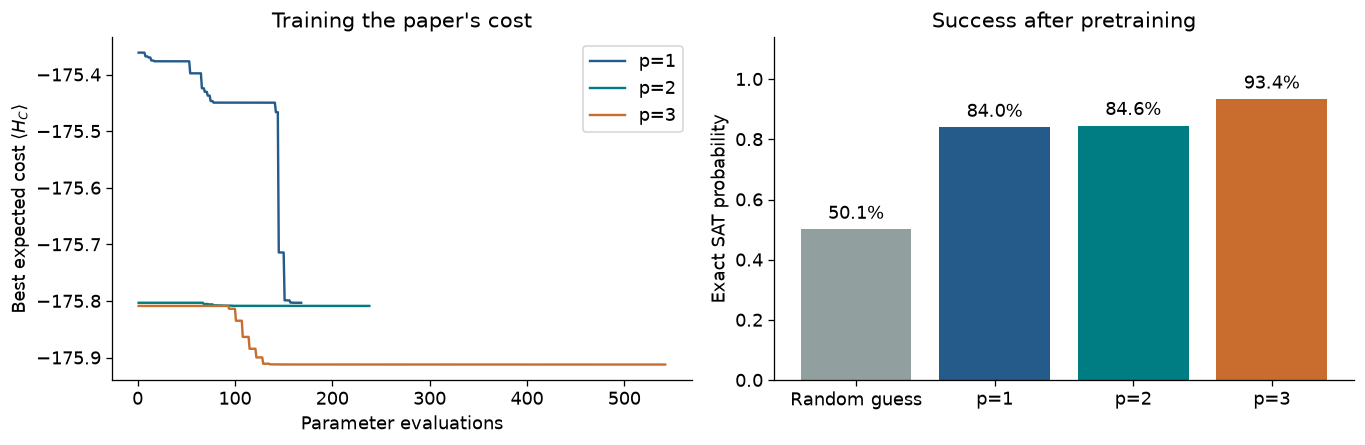

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for color, (p, result) in zip(COLORS, fits.items()):
    history = result['history']
    axes[0].plot(history[:,0], np.minimum.accumulate(history[:,1]),
                 color=color, label=f'p={p}')
axes[0].set(xlabel='Parameter evaluations', ylabel=r'Best expected cost $\langle H_C\rangle$',
            title="Training the paper's cost")
axes[0].legend()
success_values = [uniform_success]+[fits[p]['success'] for p in P_VALUES]
bars = axes[1].bar(['Random guess', 'p=1', 'p=2', 'p=3'], success_values,
                   color=['#929f9f', *COLORS])
axes[1].bar_label(bars, labels=[f'{100*v:.1f}%' for v in success_values], padding=4)
axes[1].set(ylabel='Exact SAT probability', ylim=(0, 1.14),
            title='Success after pretraining')
fig.tight_layout()
fig.savefig(OUTPUT/'training_and_depth.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

In [12]:
selected = fits[P_SELECTED]
gammas, betas = selected['gammas'], selected['betas']
show_table([r for r in parameter_rows if r['p'] == P_SELECTED])
qaoa_qc = qaoa_circuit(N, clauses, gammas, betas)
psi = Statevector.from_instruction(qaoa_qc).data
state_error = float(np.max(np.abs(psi-selected['state'])))
assert state_error < 1e-10  # 比较复振幅，包含整体相位。
assert np.isclose(np.abs(psi)**2 @ cost_diagonal, selected['expected_cost'], atol=1e-10)
main_pretrain_s = sum(fits[p]['train_time_s'] for p in P_VALUES if p <= P_SELECTED)
P_sat_exact = float((np.abs(psi)**2)[good].sum())
print(f'Main circuit: p={P_SELECTED}; exact P(SAT)={100*P_sat_exact:.4f}%')
print(f'Pretraining including shallower warm start: {main_pretrain_s:.4f} s')
print(f'PASS: NumPy state = Qiskit state, max amplitude error={state_error:.3g}')
print(f'Global phase (derived from gamma, not separately fitted): {float(qaoa_qc.global_phase):.6f} rad')

p,layer,gamma_rad,beta_rad
3,1,0.030251981324361535,-2.399309744564762
3,2,-5.47458259766326,-0.207078003495238
3,3,-1.9438654424711346,0.16133375283204784


Main circuit: p=3; exact P(SAT)=93.3622%
Pretraining including shallower warm start: 0.2829 s
PASS: NumPy state = Qiskit state, max amplitude error=2.8e-13
Global phase (derived from gamma, not separately fitted): 0.296852 rad


### 4.1 三层 QAOA 的实际模块顺序

每层 phaser 都包含全部 176 个 8-SAT 子句，随后对 10 根数据线施加 $R_x(\beta_\ell)$。为便于阅读，主图把每层 phaser 画成模块，实际门序仍保存在电路对象中；前面的 $C_1$ 图展开 8-literal 子句的具体操作。

每层总全局相位为 $176\gamma_\ell$，由训练角度自动得到，没有额外训练参数。

layer,gamma_rad,global_phase_rad
1,0.030251981324361535,5.32434871308763
2,-5.47458259766326,-963.5265371887338
3,-1.9438654424711346,-342.1203178749197


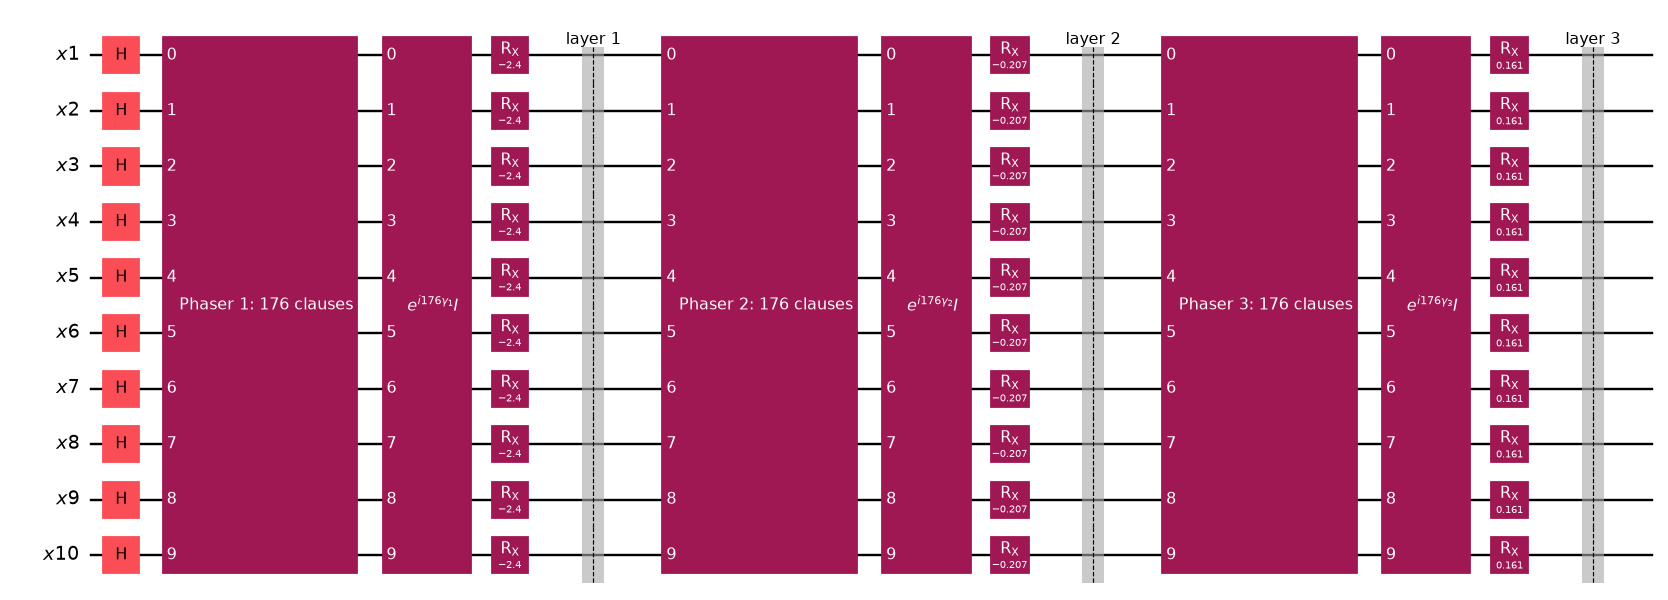

PASS: all 176 clauses in each of the 3 layers; diagram and trained state agree.


In [9]:
qaoa_visible = QuantumCircuit(*[QuantumRegister(1, f'x{i+1}') for i in range(N)], name='8-SAT QAOA p=3')
qaoa_visible.h(range(N))
phase_rows = []
for layer, (gamma, beta) in enumerate(zip(gammas, betas), 1):
    phaser = phaser_circuit(N, clauses, gamma)
    phase = float(phaser.global_phase)
    phaser.global_phase = 0.
    qaoa_visible.append(phaser.to_gate(label=f'Phaser {layer}: {M} clauses'), range(N))
    identity = QuantumCircuit(N, name='global_phase')
    identity.global_phase = phase
    qaoa_visible.append(identity.to_gate(label=rf'$e^{{i{M}\gamma_{layer}}} I$'), range(N))
    qaoa_visible.compose(mixer_circuit(N, beta), inplace=True)
    qaoa_visible.barrier(label=f'layer {layer}')
    phase_rows.append({'layer':layer, 'gamma_rad':float(gamma), 'global_phase_rad':float(M*gamma)})
visible_state = Statevector.from_instruction(qaoa_visible).data
circuit_view_error = float(np.max(np.abs(visible_state-psi)))
assert circuit_view_error < 1e-9
show_table(phase_rows)
fig = qaoa_visible.draw('mpl', fold=-1, scale=.75)
fig.savefig(OUTPUT/'qaoa_full_explicit_global_phase.png', dpi=160, bbox_inches='tight')
fig.savefig(OUTPUT/'qaoa_full_explicit_global_phase.svg', bbox_inches='tight')
display(fig); plt.close(fig)
print('PASS: all 176 clauses in each of the 3 layers; diagram and trained state agree.')

## 5. Sparrow：同一份 8-SAT 输入

调用本机原生 Sparrow，并将每次输出代回全部 176 个子句核验。时间包含进程启动、求解与输出。

In [14]:
SPARROW_EXE = Path(os.environ.get('SPARROW_EXE',
    Path('D:/桌面/hkust/urop/code/classical_solvers/sparrow/bin/sparrow.exe'))).expanduser().resolve()
if not SPARROW_EXE.is_file():
    raise FileNotFoundError('Set SPARROW_EXE to the installed Sparrow executable.')

def ascii_temp_root():
    for value in [os.environ.get('TMP'), os.environ.get('TEMP'), tempfile.gettempdir()]:
        if value and Path(value).is_dir() and str(Path(value).resolve()).isascii():
            return Path(value).resolve()
    raise RuntimeError('Sparrow needs an existing writable ASCII-only temporary folder.')

def check_assignment(bits):
    return len(bits) == N and all(bit in (0, 1) for bit in bits) and all(
        any(bool(bits[i]) == positive for i, positive in clause) for clause in clauses)

def run_sparrow(seed):
    with tempfile.TemporaryDirectory(prefix='sparrow_report_', dir=ascii_temp_root()) as folder:
        temp_cnf = Path(folder)/'instance.cnf'
        temp_cnf.write_text(cnf_text, encoding='ascii')
        command = [str(SPARROW_EXE), '--randomc', '1', '-a', '--runs', '1',
                   '--maxflips', '1000000', str(temp_cnf), str(seed)]
        start = time.perf_counter_ns()
        try:
            proc = subprocess.run(command, capture_output=True, text=True,
                                  encoding='utf-8', errors='replace', timeout=5, check=False,
                                  creationflags=getattr(subprocess, 'CREATE_NO_WINDOW', 0))
        except subprocess.TimeoutExpired:
            return {'seed':seed, 'status':'UNKNOWN', 'model_valid':False,
                    'model_bitstring':'', 'wall_time_s':(time.perf_counter_ns()-start)*1e-9,
                    'stdout':''}
        elapsed = (time.perf_counter_ns()-start)*1e-9
    if proc.returncode not in (0, 10):
        raise RuntimeError(f'Sparrow failed: {proc.stderr}')
    sat = bool(re.search(r'^\s*s\s+SATISFIABLE\s*$', proc.stdout, re.MULTILINE))
    bits = [None]*N
    for line in proc.stdout.splitlines():
        if not line.lstrip().startswith('v '): continue
        for literal in map(int, line.split()[1:]):
            if literal == 0: break
            i, value = abs(literal)-1, int(literal > 0)
            if not 0 <= i < N or bits[i] not in (None, value):
                raise RuntimeError('Sparrow returned an invalid or inconsistent variable.')
            bits[i] = value
    valid = sat and check_assignment(bits)
    if sat and not valid: raise RuntimeError('Sparrow model failed independent clause checks.')
    return {'seed':seed, 'status':'SAT' if valid else 'UNKNOWN', 'model_valid':valid,
            'model_bitstring':''.join(map(str, bits[::-1])) if valid else '',
            'wall_time_s':elapsed, 'stdout':proc.stdout}

In [15]:
example = run_sparrow(seed=1)
assert example['model_valid']
print(example['stdout'].strip())
print('Qiskit-order bitstring:', example['model_bitstring'])
print('All clauses satisfied:', example['model_valid'])
print(f'Launch-inclusive wall time: {1000*example["wall_time_s"]:.3f} ms')

s SATISFIABLE
v 1 2 -3 -4 5 -6 -7 -8 -9 -10 0
Qiskit-order bitstring: 0000010011
All clauses satisfied: True
Launch-inclusive wall time: 180.114 ms


`v` 行的正整数表示变量取 1，负整数表示取 0；末尾 0 是结束标记。比特串从左到右按 x10…x1 排列。下面统计 1000 个独立种子的真实输出。

In [16]:
sparrow_results = [run_sparrow(seed) for seed in range(1, SPARROW_RUNS+1)]
sparrow_successes = sum(r['model_valid'] for r in sparrow_results)
sparrow_median_s = statistics.median(r['wall_time_s'] for r in sparrow_results)
print(f'Verified SAT answers: {sparrow_successes}/{SPARROW_RUNS}')
print(f'Median launch-inclusive time: {1000*sparrow_median_s:.3f} ms')
write_csv('sparrow_runs.csv', [{k:r[k] for k in
    ['seed', 'status', 'model_valid', 'model_bitstring', 'wall_time_s']}
    for r in sparrow_results])

Verified SAT answers: 1000/1000
Median launch-inclusive time: 25.158 ms


## 6. 1000 次抽样与 Sparrow 统计

固定重新训练后的 p=3 电路抽取 1000 个答案，Sparrow 独立运行 1000 次。每个答案核验全部 176 条规则，经验频率与精确概率分别记录。

method,valid_answers,samples_or_runs,observed_success
QAOA (p=3),935,1000,0.935
Sparrow,1000,1000,1.0


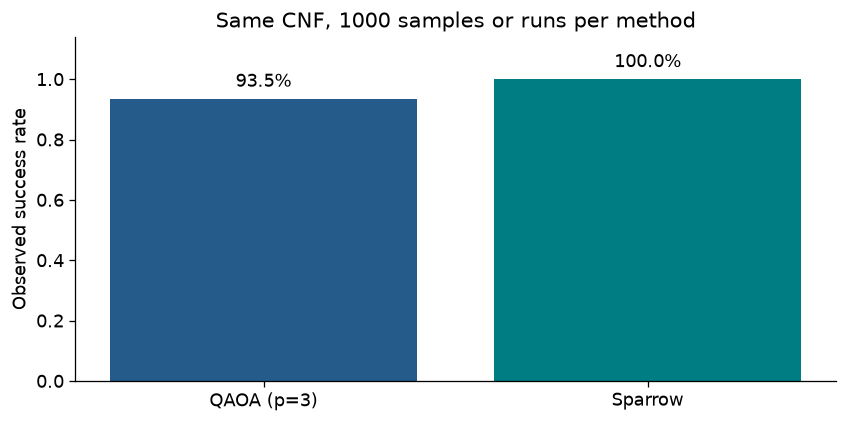

In [17]:
def sample_state(state, shots, rng):
    probabilities = np.abs(state)**2
    probabilities /= probabilities.sum()
    return rng.multinomial(int(shots), probabilities)

q_counts = sample_state(psi, SHOTS, np.random.default_rng(SHOT_SEED))
sampled_states = np.repeat(np.arange(1<<N), q_counts)
q_successes = sum(check_assignment([(int(x)>>i)&1 for i in range(N)])
                  for x in sampled_states)
assert q_successes == int(q_counts[good].sum())
accuracy_rows = [
    {'method':f'QAOA (p={P_SELECTED})', 'valid_answers':q_successes,
     'samples_or_runs':SHOTS, 'observed_success':q_successes/SHOTS},
    {'method':'Sparrow', 'valid_answers':sparrow_successes,
     'samples_or_runs':SPARROW_RUNS, 'observed_success':sparrow_successes/SPARROW_RUNS}]
show_table(accuracy_rows)
write_csv('success_accuracy.csv', accuracy_rows)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar([r['method'] for r in accuracy_rows],
              [r['observed_success'] for r in accuracy_rows], color=COLORS[:2])
ax.bar_label(bars, labels=[f'{100*r["observed_success"]:.1f}%' for r in accuracy_rows], padding=5)
ax.set(ylabel='Observed success rate', ylim=(0, 1.14),
       title='Same CNF, 1000 samples or runs per method')
fig.tight_layout()
fig.savefig(OUTPUT/'observed_success.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

In [18]:
summary = {'n':N, 'm':M, 'k':K, 'cnf_name':CNF_NAME,
    'cnf_sha256':hashlib.sha256((PROJECT/'data'/CNF_NAME).read_bytes()).hexdigest(), 'p_selected':P_SELECTED,
    'objective':'paper_v1_Eq4_H_C', 'mean_H_C':selected['expected_cost'],
    'P_sat_exact':P_sat_exact, 'QAOA_valid_samples':q_successes,
    'Sparrow_valid_runs':sparrow_successes, 'trials_per_method':SHOTS,
    'main_pretrain_s':main_pretrain_s, 'sparrow_median_wall_s':sparrow_median_s,
    'phase_max_error':phase_error, 'state_max_error':state_error,
    'clause_view_max_error':clause_view_error,
    'circuit_view_max_error':circuit_view_error}
(OUTPUT/'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
assert np.isclose(np.sum(np.abs(psi)**2), 1)
assert sum(q_counts) == SHOTS
assert all(-M-1e-9 <= r['mean_H_C'] <= 0 for r in training_rows)
print('Report demo completed. Results saved in:', OUTPUT)

Report demo completed. Results saved in: C:\Users\yanxi\.codex\.chatgpt-projects\g-p-6ab3fde64d14819191c93e2b0a8fa871\work\eight_sat_n10_m176_20261116\qaoa_aa_3sat\results\8sat_n10_m176\pretrain
